<a href="https://colab.research.google.com/github/TheaHubner/RutgersGIS/blob/main/ps2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This is my Colab. Work will be saved in Github and edited here. I can look at version history on Github and here under "File."

My project (unless I get access to my other dataset in reasonable time) will use a dataset I aqcuired from The Gun Violence Archive. This dataset contains all incidents of purposeful gun violence in America within the last 10 years. These incidents can be further divided into classifications (Purposeful Injury, Purposeful Death, Mass Shootings, Armed Robbery, and Domestic). I intend to explore the rates of these events in counties across America to identify counties with significantly high incident rates and to identify counties for which Domestic incidents are significantly different than the rates of all other types of violence.
I will continue to develop more specific research questions with Dr. Stansfield as we go.

Right now, my hypothesis is simply that rates of various types of gun violence rise parallel. I also hypothesis that counties with significantly higher rates of Domestic incidents will be rural counties.

Problem Set 2

First step: Setup so that PS2 can run on its own

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import mapclassify

df = pd.read_excel('/content/drive/MyDrive/My Documents/Career Documents/Rutgers University/GIS/GVA Excel.xlsx', header=6)

dead_col = [c for c in df.columns if 'Shot' in c and 'Dead' in c][0]
injured_col = [c for c in df.columns if 'Shot' in c and 'Wounded' in c][0]

print(df.shape)
print(dead_col, '|', injured_col)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(453387, 21)
Shot - Dead (murder, accidental, or suicide) | Shot - Wounded/Injured


In [2]:
def classify_incident(row):
    if row['Domestic Violence'] == 'x':
        return 'Domestic Violence'
    elif row['Armed Robbery'] == 'x':
        return 'Armed Robbery'
    elif row['Mass Shooting'] == 'x':
        return 'Mass Shooting'
    elif row[dead_col] == 'x':
        return 'Willful Death'
    elif row[injured_col] == 'x':
        return 'Willful Injury'
    else:
        return None

df['Incident Type'] = df.apply(classify_incident, axis=1)

print(df['Incident Type'].value_counts(dropna=False))

Incident Type
Willful Injury       249480
Willful Death        146954
Domestic Violence     28707
Armed Robbery         23159
Mass Shooting          5087
Name: count, dtype: int64


In [3]:
# drop all of the unnecessary columns
df = df.drop(columns=[
    'Incident ID',
    'City',
    'Business or School',
    'Address',
    '# Victims Killed',
    '# Victims Injured',
    '# Suspect Killed',
    '# Suspects Injured',
    '# Suspects Unharmed',
    '# Suspects Arrested',
    'Accidental',
    'Mass Shooting',
    'Armed Robbery',
    'Domestic Violence',
    dead_col,
    injured_col,
])

# remove incidents with no coordinates (can't be placed in a county)
df = df.dropna(subset=['Latitude', 'Longitude'])

print(df.shape)
print(df.columns.tolist())

(453326, 6)
['Date', 'State', 'Latitude', 'Longitude', 'Incident Characteristics', 'Incident Type']


In [4]:
from shapely.geometry import Point

# load the county shapefile (TIGER 2024)
!wget -q https://www2.census.gov/geo/tiger/TIGER2024/COUNTY/tl_2024_us_county.zip -O counties.zip
!unzip -q -o counties.zip -d counties
counties = gpd.read_file('counties/tl_2024_us_county.shp')
counties = counties.to_crs('EPSG:4326')

# turn lat/long into point geometries
geometry = [Point(xy) for xy in zip(df['Longitude'], df['Latitude'])]
incidents_gdf = gpd.GeoDataFrame(df, geometry=geometry, crs='EPSG:4326')

# spatial join: find which county polygon each incident falls inside
joined = gpd.sjoin(incidents_gdf, counties[['GEOID', 'NAME', 'geometry']], how='left', predicate='within')

print(counties.shape)
print(joined.shape)
print(joined['GEOID'].isna().sum())

(3235, 19)
(453326, 10)
0


In [5]:
# count incidents per county per type, then spread the types into columns
county_counts = joined.groupby(['GEOID', 'NAME', 'Incident Type']).size().reset_index(name='Count')

county_wide = county_counts.pivot_table(
    index=['GEOID', 'NAME'],
    columns='Incident Type',
    values='Count',
    fill_value=0
).reset_index()

# start from the full county list so counties with zero incidents are kept
final = counties[['GEOID', 'NAME']].merge(county_wide, on=['GEOID', 'NAME'], how='left')
final = final.fillna(0)

# drop Puerto Rico (state code 72)
final = final[final['GEOID'].str[:2] != '72']

# remove decimals from the counts
type_cols = ['Armed Robbery', 'Domestic Violence', 'Mass Shooting', 'Willful Death', 'Willful Injury']
final[type_cols] = final[type_cols].astype(int)

print(final.shape)
print(final[type_cols].sum().sum())
print(final[final['GEOID'] == '17031'])

(3157, 7)
453326
     GEOID  NAME  Armed Robbery  Domestic Violence  Mass Shooting  \
643  17031  Cook           1108                526            416   

     Willful Death  Willful Injury  
643           6568           23388  


In [6]:
# read RUCC (rurality + 2020 population) and SAIPE (income)
rucc = pd.read_excel('/content/drive/MyDrive/My Documents/Career Documents/Rutgers University/GIS/RUCC.xlsx')
saipe = pd.read_excel('/content/drive/MyDrive/My Documents/Career Documents/Rutgers University/GIS/SAIPE.xls', header=3)

# SAIPE: keep county rows only (drop the state/US summary rows), keep the columns we need
saipe_counties = saipe[saipe['County FIPS Code'] != 0].copy()
saipe_clean = saipe_counties[['State FIPS Code', 'County FIPS Code', 'Postal Code', 'Name', 'Median Household Income', 'Poverty Percent, All Ages']].copy()

# build 5-character FIPS codes so the tables can be joined
saipe_clean['FIPS'] = (
    saipe_clean['State FIPS Code'].astype(str).str.zfill(2) +
    saipe_clean['County FIPS Code'].astype(str).str.zfill(3)
)
rucc['FIPS'] = rucc['FIPS'].astype(str).str.zfill(5)

# merge into one table
master = final.rename(columns={'GEOID': 'FIPS'})
master = master.merge(rucc[['FIPS', 'Population_2020', 'RUCC_2023']], on='FIPS', how='left', indicator='rucc_merge')
master = master.merge(saipe_clean[['FIPS', 'Median Household Income']], on='FIPS', how='left', indicator='saipe_merge')

print(master['rucc_merge'].value_counts())
print(master['saipe_merge'].value_counts())

# drop the 13 territories that SAIPE doesn't cover
master = master[master['saipe_merge'] != 'left_only'].copy()
master = master.drop(columns=['rucc_merge', 'saipe_merge'])

# incidents per 100k residents (2020 population)
for col in type_cols:
    master[f'{col} per 100k'] = (master[col] / master['Population_2020']) * 100000

master['Total Incidents'] = master[type_cols].sum(axis=1)
master['Total Incidents per 100k'] = (master['Total Incidents'] / master['Population_2020']) * 100000

print(master.shape)
print(master.columns.tolist())

rucc_merge
both          3157
left_only        0
right_only       0
Name: count, dtype: int64
saipe_merge
both          3144
left_only       13
right_only       0
Name: count, dtype: int64
(3144, 17)
['FIPS', 'NAME', 'Armed Robbery', 'Domestic Violence', 'Mass Shooting', 'Willful Death', 'Willful Injury', 'Population_2020', 'RUCC_2023', 'Median Household Income', 'Armed Robbery per 100k', 'Domestic Violence per 100k', 'Mass Shooting per 100k', 'Willful Death per 100k', 'Willful Injury per 100k', 'Total Incidents', 'Total Incidents per 100k']


In [7]:
# attach county shapes to the master table
map_gdf = counties[['GEOID', 'geometry']].merge(master, left_on='GEOID', right_on='FIPS', how='inner')

# state outlines for thicker borders on the maps
states = counties.dissolve(by='STATEFP')

# counties with and without domestic violence incidents
dv_zero = map_gdf[map_gdf['Domestic Violence'] == 0]
dv_nonzero = map_gdf[map_gdf['Domestic Violence'] > 0]

print(map_gdf.shape)
print('counties with 0 DV incidents:', len(dv_zero))
print('counties with 1+ DV incidents:', len(dv_nonzero))
print(dv_nonzero['Domestic Violence per 100k'].describe())

(3144, 19)
counties with 0 DV incidents: 855
counties with 1+ DV incidents: 2289
count    2289.000000
mean       13.023003
std        10.872292
min         0.579104
25%         5.790187
50%         9.960159
75%        17.100594
max       131.578947
Name: Domestic Violence per 100k, dtype: float64


Setup is complete!
The next is my first side-by-side comparing domestic incidents (per capita) with median income.

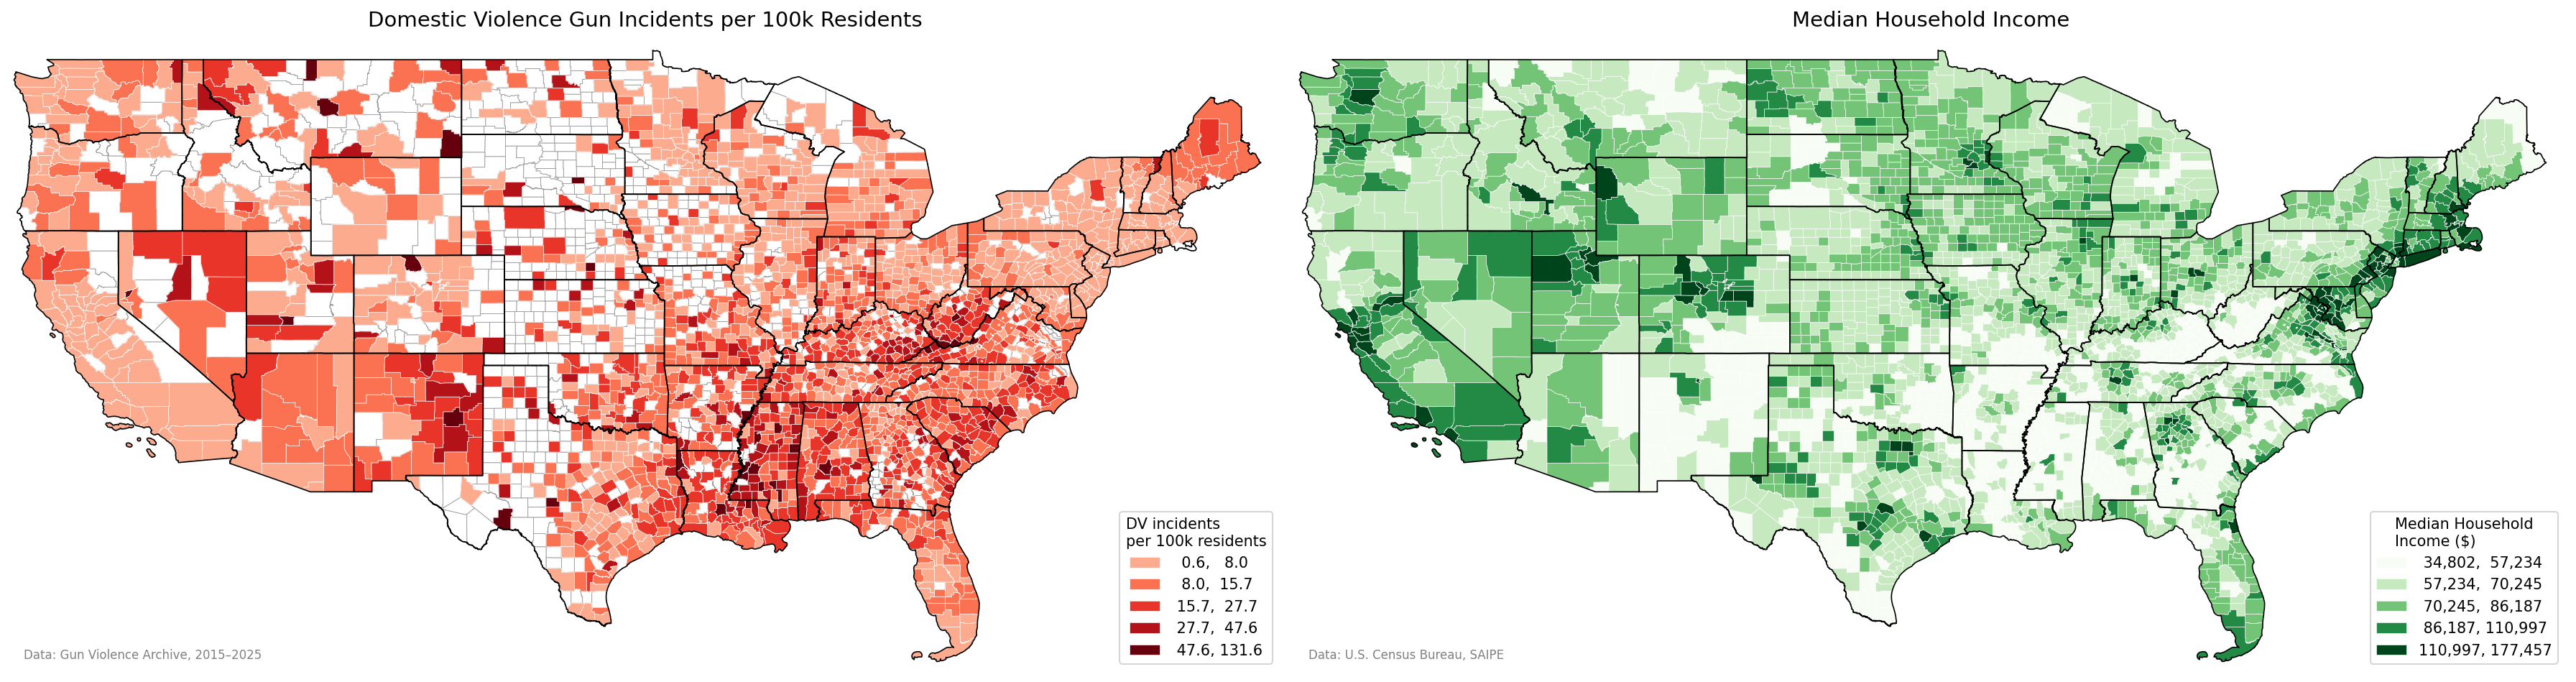

In [8]:
import matplotlib.colors as mcolors

# lighter shades were too pale before, so start the color ramp darker
reds_full = plt.get_cmap('Reds')
reds_truncated = mcolors.LinearSegmentedColormap.from_list(
    'reds_truncated', reds_full(np.linspace(0.3, 1.0, 256))
)

# income needs to be numeric (Kalawao, HI has no value and becomes blank)
map_gdf['Median Household Income'] = pd.to_numeric(map_gdf['Median Household Income'], errors='coerce')

fig, axs = plt.subplots(1, 2, figsize=(24, 8), dpi=150)

# left: DV incidents per 100k residents
dv_zero.plot(ax=axs[0], color='white', edgecolor='#999999', linewidth=0.4)
dv_nonzero.plot(
    ax=axs[0], column='Domestic Violence per 100k', cmap=reds_truncated,
    scheme='natural_breaks', k=5,
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': 'DV incidents\nper 100k residents', 'loc': 'lower right', 'fmt': '{:,.1f}'}
)
axs[0].set_title('Domestic Violence Gun Incidents per 100k Residents', fontsize=14)

# right: median household income
map_gdf.plot(
    ax=axs[1], column='Median Household Income', cmap='Greens',
    scheme='natural_breaks', k=5,
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': 'Median Household\nIncome ($)', 'loc': 'lower right', 'fmt': '{:,.0f}'}
)
axs[1].set_title('Median Household Income', fontsize=14)

for ax in axs:
    states.boundary.plot(ax=ax, color='black', linewidth=0.8)
    ax.set_xlim(-125, -66)
    ax.set_ylim(24, 50)
    ax.axis('off')

axs[0].text(0.01, 0.02, 'Data: Gun Violence Archive, 2015–2025', transform=axs[0].transAxes, fontsize=8, color='gray')
axs[1].text(0.01, 0.02, 'Data: U.S. Census Bureau, SAIPE', transform=axs[1].transAxes, fontsize=8, color='gray')

plt.tight_layout()
plt.show()

The next two maps also look at domestic incidents and median income, but it looks at total domestic incidents rather than per capita data.

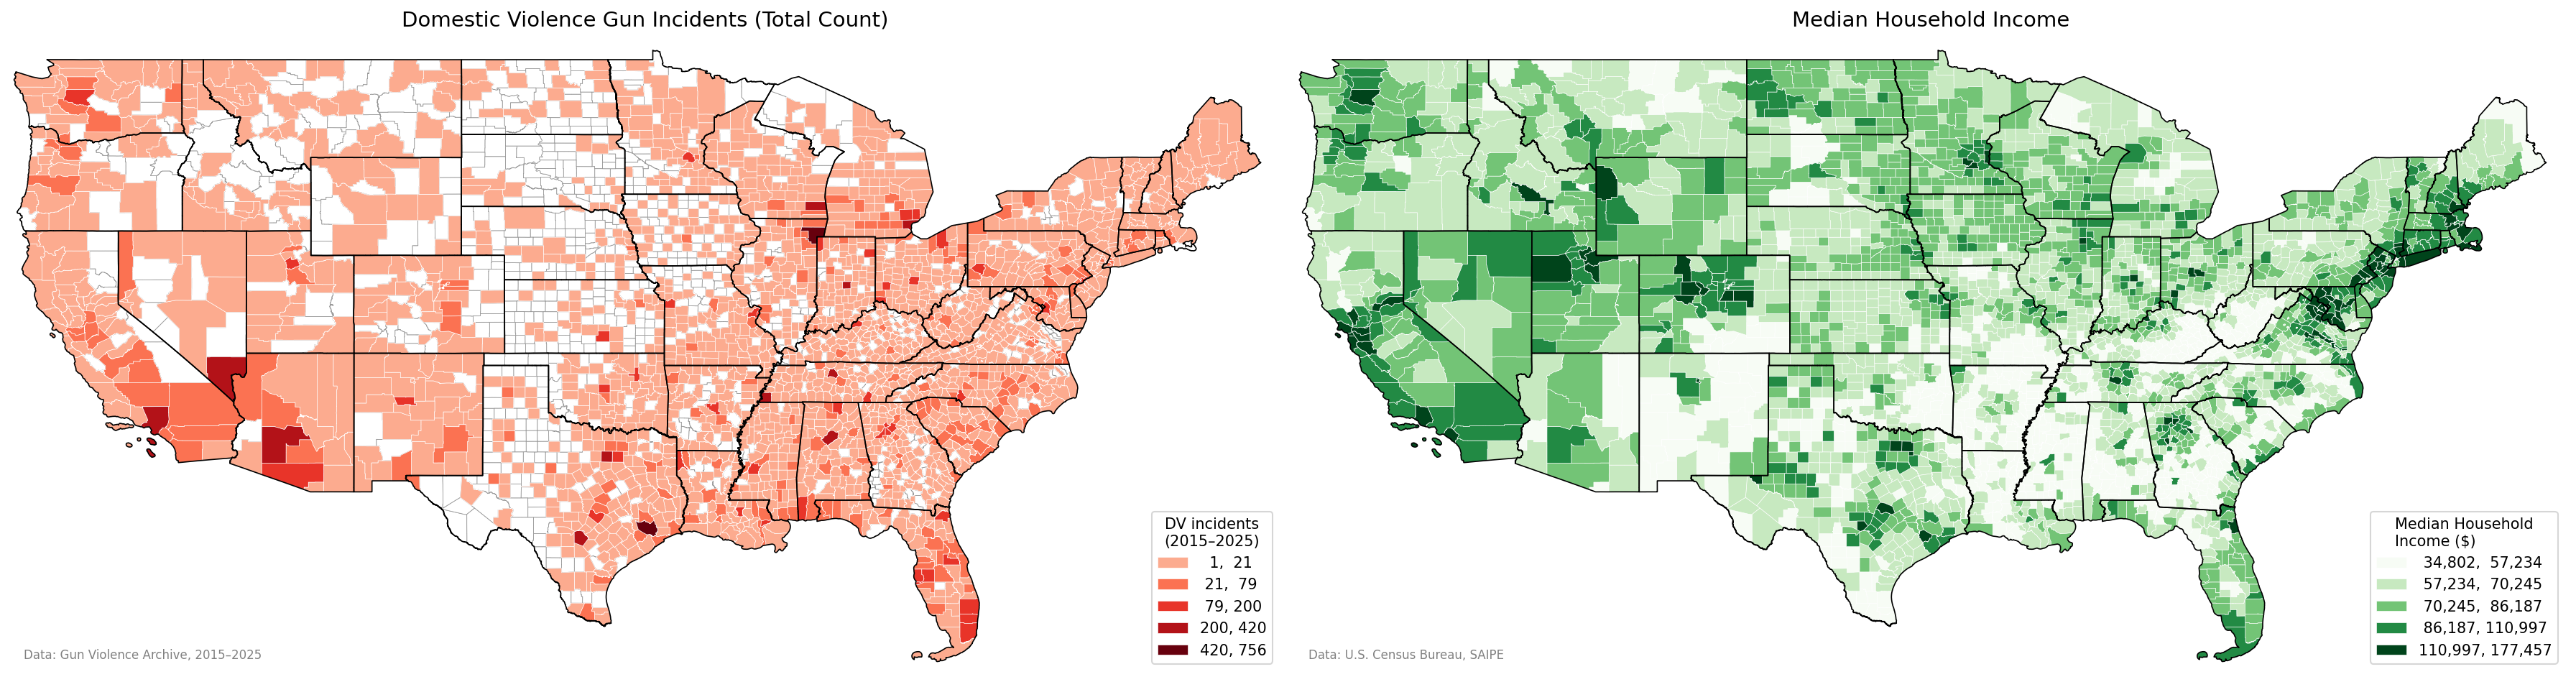

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(24, 8), dpi=150)

# left: raw DV incident counts
dv_zero.plot(ax=axs[0], color='white', edgecolor='#999999', linewidth=0.4)
dv_nonzero.plot(
    ax=axs[0], column='Domestic Violence', cmap=reds_truncated,
    scheme='natural_breaks', k=5,
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': 'DV incidents\n(2015–2025)', 'loc': 'lower right', 'fmt': '{:,.0f}'}
)
axs[0].set_title('Domestic Violence Gun Incidents (Total Count)', fontsize=14)

# right: median household income
map_gdf.plot(
    ax=axs[1], column='Median Household Income', cmap='Greens',
    scheme='natural_breaks', k=5,
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': 'Median Household\nIncome ($)', 'loc': 'lower right', 'fmt': '{:,.0f}'}
)
axs[1].set_title('Median Household Income', fontsize=14)

for ax in axs:
    states.boundary.plot(ax=ax, color='black', linewidth=0.8)
    ax.set_xlim(-125, -66)
    ax.set_ylim(24, 50)
    ax.axis('off')

axs[0].text(0.01, 0.02, 'Data: Gun Violence Archive, 2015–2025', transform=axs[0].transAxes, fontsize=8, color='gray')
axs[1].text(0.01, 0.02, 'Data: U.S. Census Bureau, SAIPE', transform=axs[1].transAxes, fontsize=8, color='gray')

plt.tight_layout()
plt.show()

Below this box are the scatterplots. One for DV incidents per capita and one for total incidents. Just like before, I also deleted all counties with under 20,000 events and ran the per capita again, to delete noise from tiny counties.

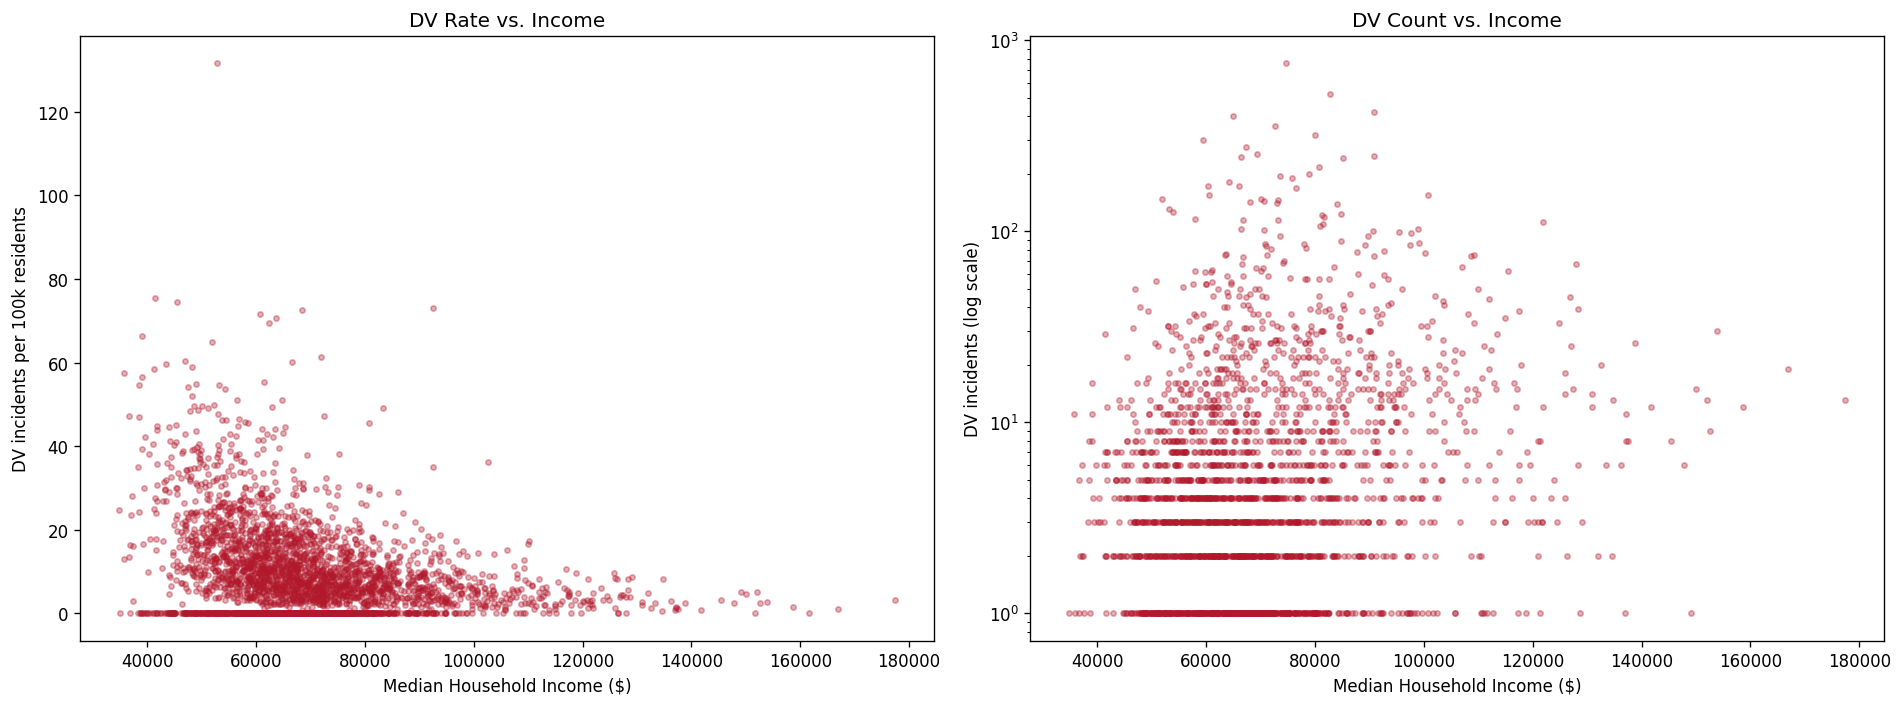

Rate vs income, all counties:    rho = -0.253, p = 5.7e-47
Count vs income, all counties:   rho = 0.143, p = 7.7e-16
Rate vs income, pop >= 20,000:   rho = -0.459, p = 1.6e-95  (n = 1816)


In [10]:
from scipy import stats

plot_df = map_gdf[['NAME', 'Domestic Violence', 'Domestic Violence per 100k',
                   'Median Household Income', 'Population_2020']].dropna(subset=['Median Household Income'])

fig, axs = plt.subplots(1, 2, figsize=(16, 6), dpi=120)

# left: DV rate vs income
axs[0].scatter(plot_df['Median Household Income'], plot_df['Domestic Violence per 100k'],
               s=10, alpha=0.35, color='#b2182b')
axs[0].set_xlabel('Median Household Income ($)')
axs[0].set_ylabel('DV incidents per 100k residents')
axs[0].set_title('DV Rate vs. Income')

# right: DV count vs income (log scale, counties with 1+ incidents)
nz = plot_df[plot_df['Domestic Violence'] > 0]
axs[1].scatter(nz['Median Household Income'], nz['Domestic Violence'],
               s=10, alpha=0.35, color='#b2182b')
axs[1].set_yscale('log')
axs[1].set_xlabel('Median Household Income ($)')
axs[1].set_ylabel('DV incidents (log scale)')
axs[1].set_title('DV Count vs. Income')

plt.tight_layout()
plt.show()

# correlation tests
rho, p = stats.spearmanr(plot_df['Median Household Income'], plot_df['Domestic Violence per 100k'])
print(f'Rate vs income, all counties:    rho = {rho:.3f}, p = {p:.2g}')

rho, p = stats.spearmanr(plot_df['Median Household Income'], plot_df['Domestic Violence'])
print(f'Count vs income, all counties:   rho = {rho:.3f}, p = {p:.2g}')

big = plot_df[plot_df['Population_2020'] >= 20000]
rho, p = stats.spearmanr(big['Median Household Income'], big['Domestic Violence per 100k'])
print(f'Rate vs income, pop >= 20,000:   rho = {rho:.3f}, p = {p:.2g}  (n = {len(big)})')

Alright. So the scatterplots above show:
1. The first one, per capita rate, demonstrates that counties with lower median income tend to have higher rates of DV incidents. (The row on 0 is counties with 0 DV incidents). It's not a particularly useful correlation though at -.253 but it's definitely 'real' (tiny P values because there are so many counties so the relationship may be weak but it's definitely not wrong).
2. The second one shows the total count and demonstrates that most counties have low rates of DV incidents, but the relationship is very weak at .143. The countries with higher rates are median income counties because most counties are near the median.
3. Even if we remove noise from small counties, the relationship is not relevant.

But from now on, I will stick to per capita data rather than counts.

In the boxes below, I will create the same side-by-side map and scatterplots for DV incidents per capita and rurality.

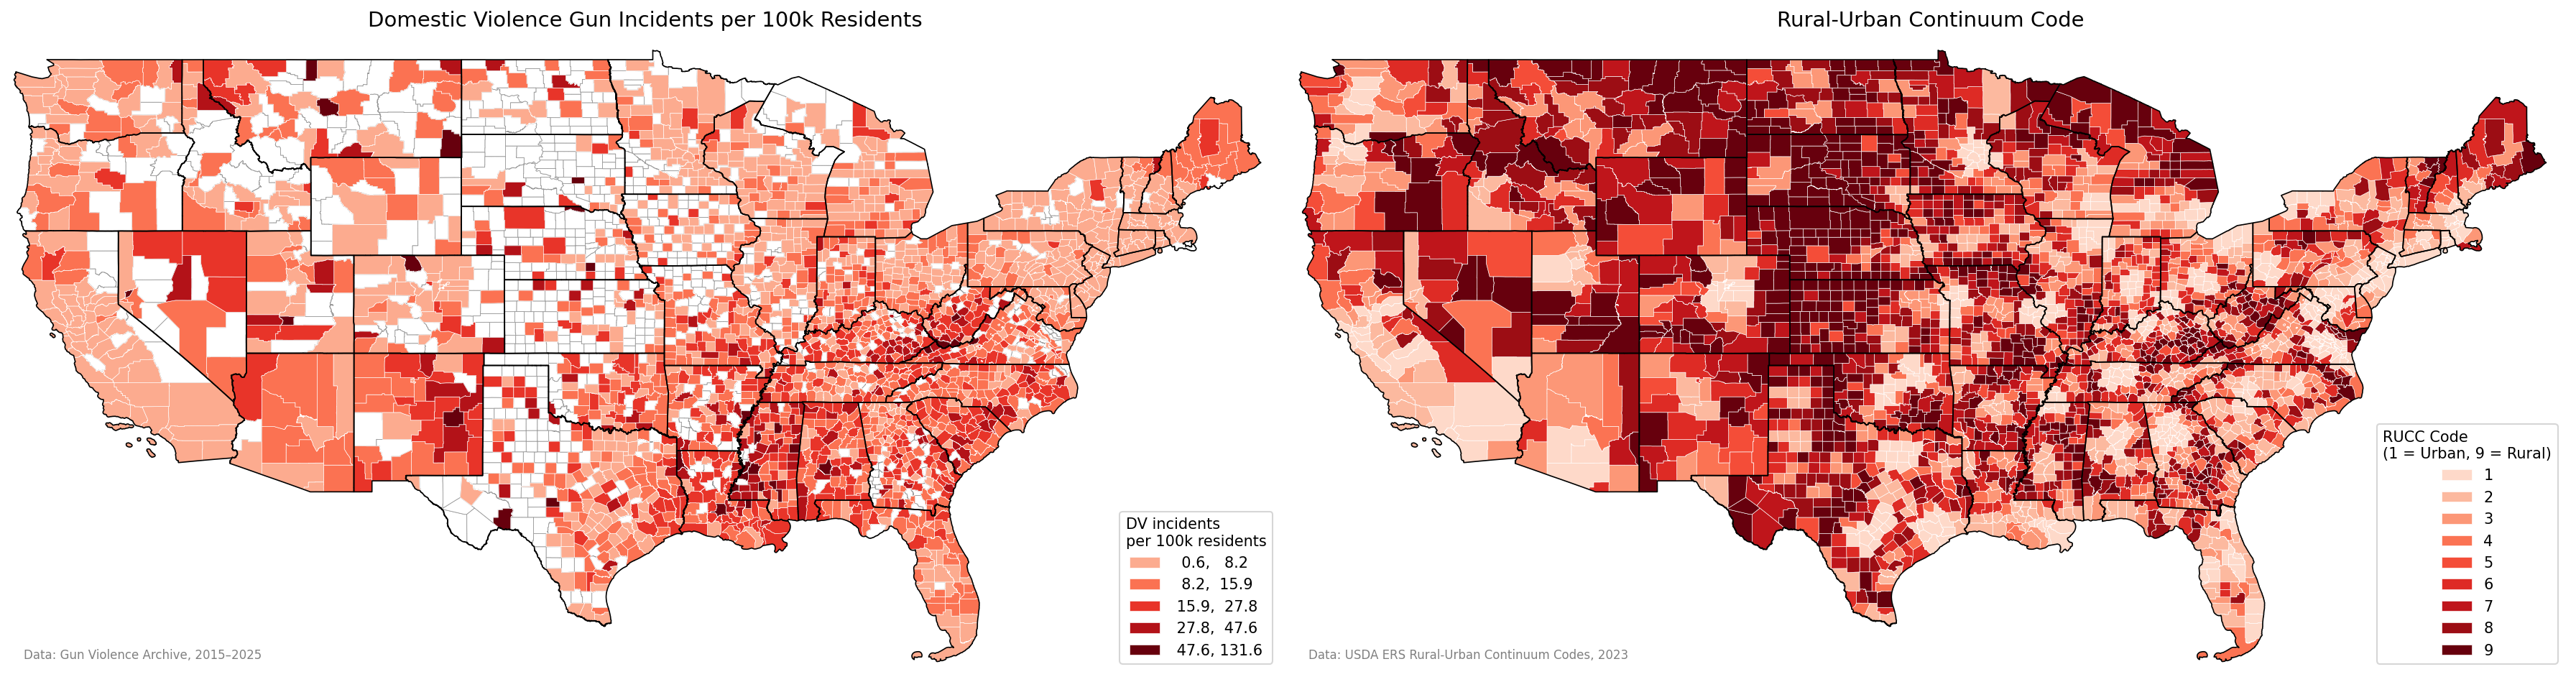

In [11]:
# one red ramp for rurality: lightest = most urban (1), darkest = most rural (9)
map_gdf['RUCC_2023'] = map_gdf['RUCC_2023'].astype(int)
rucc_cmap = mcolors.ListedColormap(plt.get_cmap('Reds')(np.linspace(0.15, 1.0, 9)))

fig, axs = plt.subplots(1, 2, figsize=(24, 8), dpi=150)

# left: DV incidents per 100k residents
dv_zero.plot(ax=axs[0], color='white', edgecolor='#999999', linewidth=0.4)
dv_nonzero.plot(
    ax=axs[0], column='Domestic Violence per 100k', cmap=reds_truncated,
    scheme='natural_breaks', k=5,
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': 'DV incidents\nper 100k residents', 'loc': 'lower right', 'fmt': '{:,.1f}'}
)
axs[0].set_title('Domestic Violence Gun Incidents per 100k Residents', fontsize=14)

# right: rural-urban continuum code, light red = urban, dark red = rural
map_gdf.plot(
    ax=axs[1], column='RUCC_2023', cmap=rucc_cmap, categorical=True,
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': 'RUCC Code\n(1 = Urban, 9 = Rural)', 'loc': 'lower right'}
)
axs[1].set_title('Rural-Urban Continuum Code', fontsize=14)

for ax in axs:
    states.boundary.plot(ax=ax, color='black', linewidth=0.8)
    ax.set_xlim(-125, -66)
    ax.set_ylim(24, 50)
    ax.axis('off')

axs[0].text(0.01, 0.02, 'Data: Gun Violence Archive, 2015–2025', transform=axs[0].transAxes, fontsize=8, color='gray')
axs[1].text(0.01, 0.02, 'Data: USDA ERS Rural-Urban Continuum Codes, 2023', transform=axs[1].transAxes, fontsize=8, color='gray')

plt.tight_layout()
plt.show()

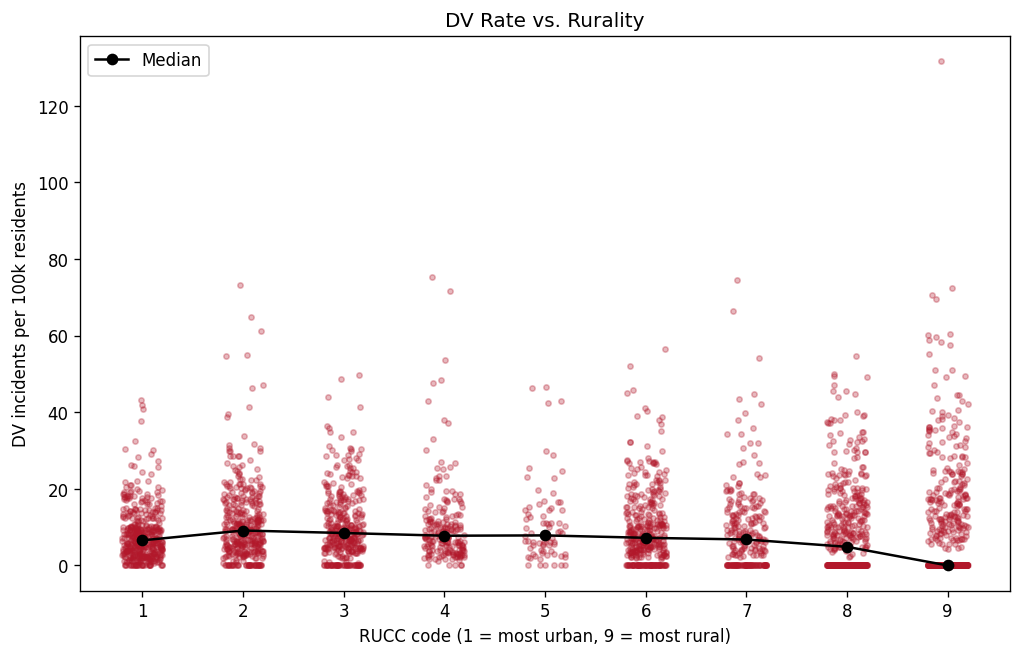

RUCC_2023
1    6.6
2    9.1
3    8.5
4    7.8
5    7.8
6    7.2
7    6.8
8    4.9
9    0.0
Name: Domestic Violence per 100k, dtype: float64
Rate vs RUCC, all counties:    rho = -0.192, p = 2.3e-27
Rate vs RUCC, pop >= 20,000:   rho = 0.062, p = 0.0084  (n = 1816)


In [12]:
rucc_df = map_gdf[['RUCC_2023', 'Domestic Violence per 100k', 'Population_2020']].dropna()

rng = np.random.default_rng(0)
jitter_x = rucc_df['RUCC_2023'] + rng.uniform(-0.2, 0.2, len(rucc_df))

fig, ax = plt.subplots(figsize=(10, 6), dpi=120)
ax.scatter(jitter_x, rucc_df['Domestic Violence per 100k'], s=10, alpha=0.3, color='#b2182b')

medians = rucc_df.groupby('RUCC_2023')['Domestic Violence per 100k'].median()
ax.plot(medians.index, medians.values, color='black', marker='o', linewidth=1.5, label='Median')

ax.set_xticks(range(1, 10))
ax.set_xlabel('RUCC code (1 = most urban, 9 = most rural)')
ax.set_ylabel('DV incidents per 100k residents')
ax.set_title('DV Rate vs. Rurality')
ax.legend()
plt.show()

print(medians.round(1))

rho, p = stats.spearmanr(rucc_df['RUCC_2023'], rucc_df['Domestic Violence per 100k'])
print(f'Rate vs RUCC, all counties:    rho = {rho:.3f}, p = {p:.2g}')

big = rucc_df[rucc_df['Population_2020'] >= 20000]
rho, p = stats.spearmanr(big['RUCC_2023'], big['Domestic Violence per 100k'])
print(f'Rate vs RUCC, pop >= 20,000:   rho = {rho:.3f}, p = {p:.2g}  (n = {len(big)})')

Does not look like rurality is a factor, moving on!


Nothing seems super interesting yet, so I will add another dataset: the ATF Bureau of Alcohol, Tobacco, Firearms, and Explosives dataset titled "Federal Firearm Listings." This is a comprehensive list of licensed firearm license sellers in the USA. Perhaps DV incidents are higher in places where firearm 'shops' are more popular (as a stand-in for number of gun owners).

Since my data spans 2015 - 2025, I am trying to find datasets with 2020 data. January 2021 is the earliest available dataset for the FFL, so that is what is used.

In [13]:
ffl_path = '/content/drive/MyDrive/My Documents/Career Documents/Rutgers University/GIS/FFL List.csv'

# skip the dashed line under the header; read everything as text to keep leading zeros
ffl = pd.read_csv(ffl_path, dtype=str, skiprows=[1], encoding='latin-1')

print(ffl.shape)
print(ffl['LIC_TYPE'].value_counts())

# build a 5-digit county FIPS = state FIPS + 3-digit county code
state_fips = dict(zip(rucc['State'], rucc['FIPS'].str[:2]))
ffl['FIPS'] = ffl['PREMISE_STATE'].map(state_fips) + ffl['LIC_CNTY'].str.zfill(3)

# do the codes match your counties?
matched = ffl['FIPS'].isin(master['FIPS'])
print('share of FFLs matching a county in master:', round(matched.mean(), 4))
print('FFLs with no state match:', ffl['FIPS'].isna().sum())
print(ffl.loc[~matched, 'PREMISE_STATE'].value_counts().head(15))

(78828, 17)
LIC_TYPE
01    52973
07    14832
02     7104
06     1864
08     1220
10      432
11      275
09      128
Name: count, dtype: int64
share of FFLs matching a county in master: 0.99
FFLs with no state match: 0
PREMISE_STATE
CT    658
PR     69
AK     20
GU     18
VI     13
DC      6
MP      3
Name: count, dtype: int64


Now let's convert the data to county-level counts per capita

In [14]:
# count all licenses per county, plus pawnbrokers (type 02) separately
all_counts = ffl.groupby('FIPS').size().rename('FFL Count')
pawn_counts = ffl[ffl['LIC_TYPE'] == '02'].groupby('FIPS').size().rename('Pawnbroker Count')
ffl_by_county = pd.concat([all_counts, pawn_counts], axis=1).reset_index()

# add to master (drop first so the cell can be rerun safely)
new_cols = ['FFL Count', 'Pawnbroker Count', 'FFLs per 100k', 'Pawnbrokers per 100k']
master = master.drop(columns=new_cols, errors='ignore')
master = master.merge(ffl_by_county, on='FIPS', how='left')
master[['FFL Count', 'Pawnbroker Count']] = master[['FFL Count', 'Pawnbroker Count']].fillna(0)  # none = 0

master['FFLs per 100k'] = master['FFL Count'] / master['Population_2020'] * 100000
master['Pawnbrokers per 100k'] = master['Pawnbroker Count'] / master['Population_2020'] * 100000

# Connecticut: ATF uses old counties, our map uses planning regions, so mark as no data
ct = master['FIPS'].str[:2] == '09'
master.loc[ct, new_cols] = np.nan

# attach to the map table
map_gdf = map_gdf.drop(columns=new_cols, errors='ignore')
map_gdf = map_gdf.merge(master[['FIPS'] + new_cols], on='FIPS', how='left')

print(master['FFLs per 100k'].describe())
print(master.loc[~ct, 'FFL Count'].sum(), 'licenses placed in counties (excluding CT)')
print(master.sort_values('FFLs per 100k', ascending=False)[['NAME', 'FIPS', 'FFL Count', 'Pawnbroker Count', 'Population_2020', 'FFLs per 100k']].head(10))
print(master.sort_values('Pawnbrokers per 100k', ascending=False)[['NAME', 'FIPS', 'Pawnbroker Count', 'Population_2020', 'Pawnbrokers per 100k']].head(10))

count    3135.000000
mean       62.021560
std        60.860597
min         0.000000
25%        29.759199
50%        47.169811
75%        74.954851
max      1562.500000
Name: FFLs per 100k, dtype: float64
78041.0 licenses placed in counties (excluding CT)
              NAME   FIPS  FFL Count  Pawnbroker Count  Population_2020  \
2453        Loving  48301        1.0               0.0               64   
1049       Harding  35021        5.0               0.0              657   
1651   Bristol Bay  02060        5.0               0.0              844   
3059       Prairie  30079        6.0               0.0             1088   
247           Lane  20101        8.0               0.0             1574   
1382        Arthur  31005        2.0               0.0              434   
2509  Powder River  30075        7.0               0.0             1694   
119       Cheyenne  08017        7.0               0.0             1748   
257      Keya Paha  31103        3.0               0.0              76

Below are the side-by-side maps for DV incidents per capita and licensed firearm dealers per capita. Like DV incidents, licensed dealers also suffer from the 'small county' problem, where small counties are overrepresented. All states are included besides Connecticut, as Connecticut is divided differently in the dataset.

Instead of natural breaks, I will use quantile breaks to solve the 'small county' problem a bit.

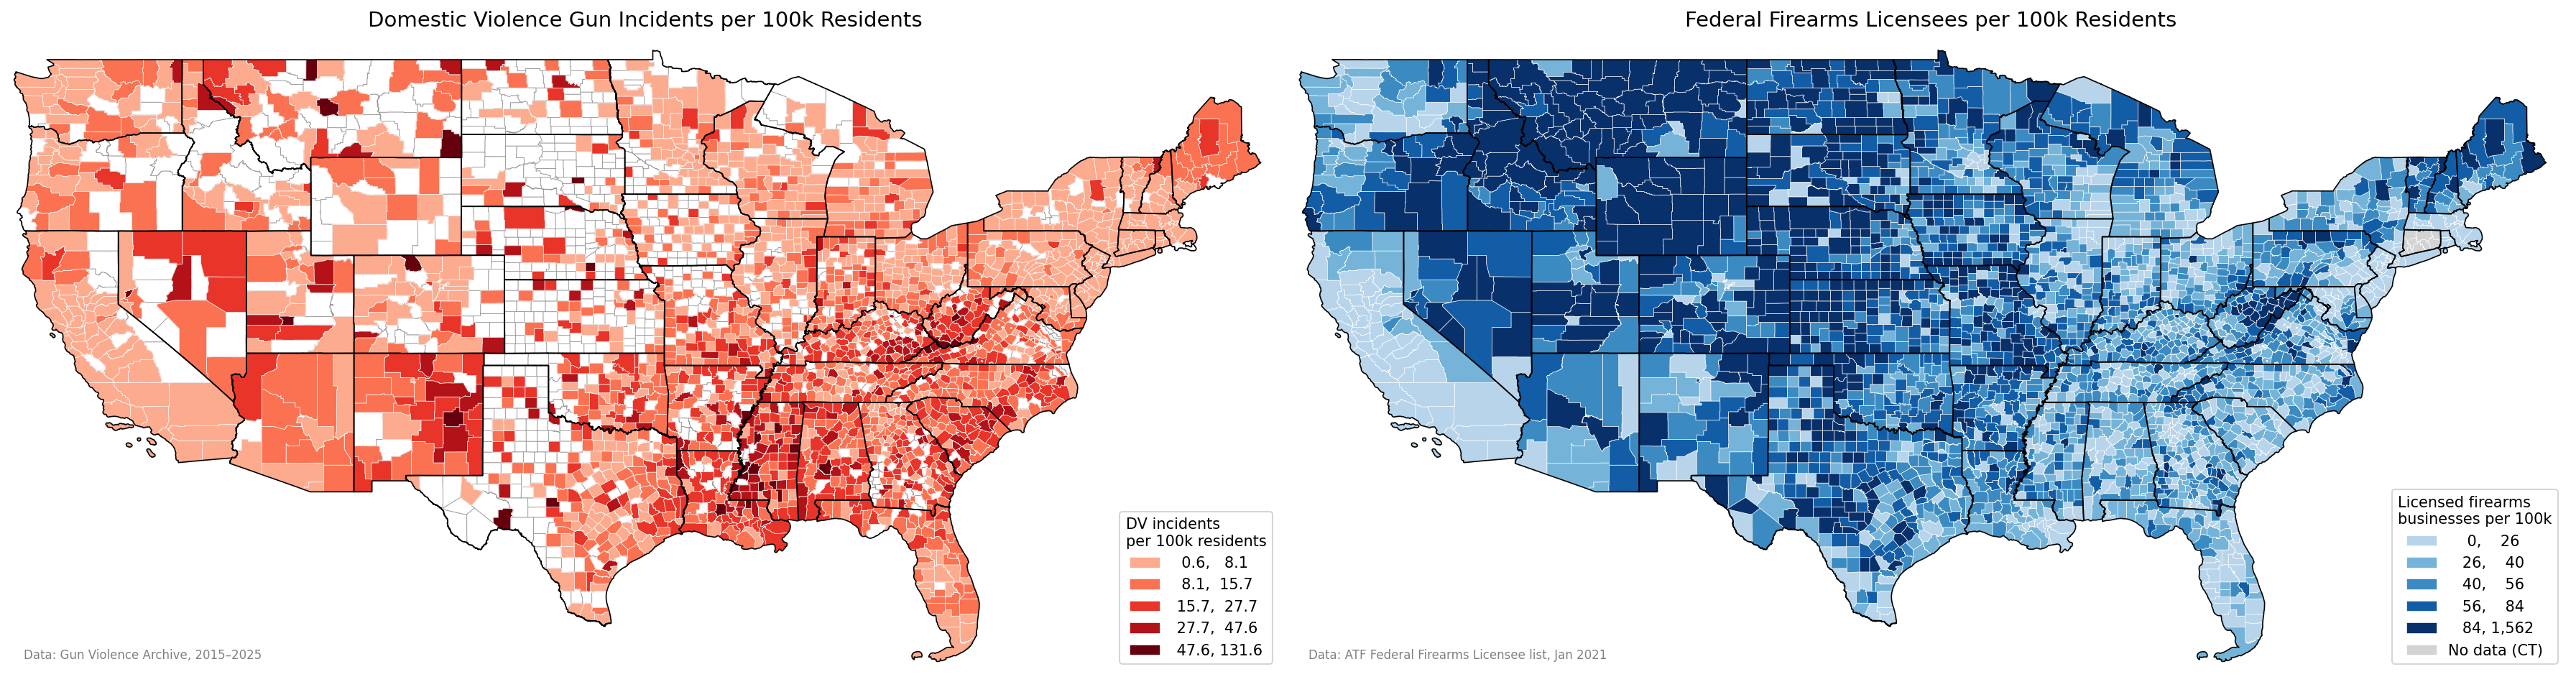

In [15]:
blues_truncated = mcolors.LinearSegmentedColormap.from_list(
    'blues_truncated', plt.get_cmap('Blues')(np.linspace(0.3, 1.0, 256))
)

fig, axs = plt.subplots(1, 2, figsize=(24, 8), dpi=150)

# left: DV incidents per 100k residents
dv_zero.plot(ax=axs[0], color='white', edgecolor='#999999', linewidth=0.4)
dv_nonzero.plot(
    ax=axs[0], column='Domestic Violence per 100k', cmap=reds_truncated,
    scheme='natural_breaks', k=5,
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': 'DV incidents\nper 100k residents', 'loc': 'lower right', 'fmt': '{:,.1f}'}
)
axs[0].set_title('Domestic Violence Gun Incidents per 100k Residents', fontsize=14)

# right: licensed firearms businesses (FFLs) per 100k residents
map_gdf.plot(
    ax=axs[1], column='FFLs per 100k', cmap=blues_truncated,
    scheme='quantiles', k=5,
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': 'Licensed firearms\nbusinesses per 100k', 'loc': 'lower right', 'fmt': '{:,.0f}'},
    missing_kwds={'color': 'lightgrey', 'label': 'No data (CT)'}
)
axs[1].set_title('Federal Firearms Licensees per 100k Residents', fontsize=14)

for ax in axs:
    states.boundary.plot(ax=ax, color='black', linewidth=0.8)
    ax.set_xlim(-125, -66)
    ax.set_ylim(24, 50)
    ax.axis('off')

axs[0].text(0.01, 0.02, 'Data: Gun Violence Archive, 2015–2025', transform=axs[0].transAxes, fontsize=8, color='gray')
axs[1].text(0.01, 0.02, 'Data: ATF Federal Firearms Licensee list, Jan 2021', transform=axs[1].transAxes, fontsize=8, color='gray')

plt.tight_layout()
plt.show()

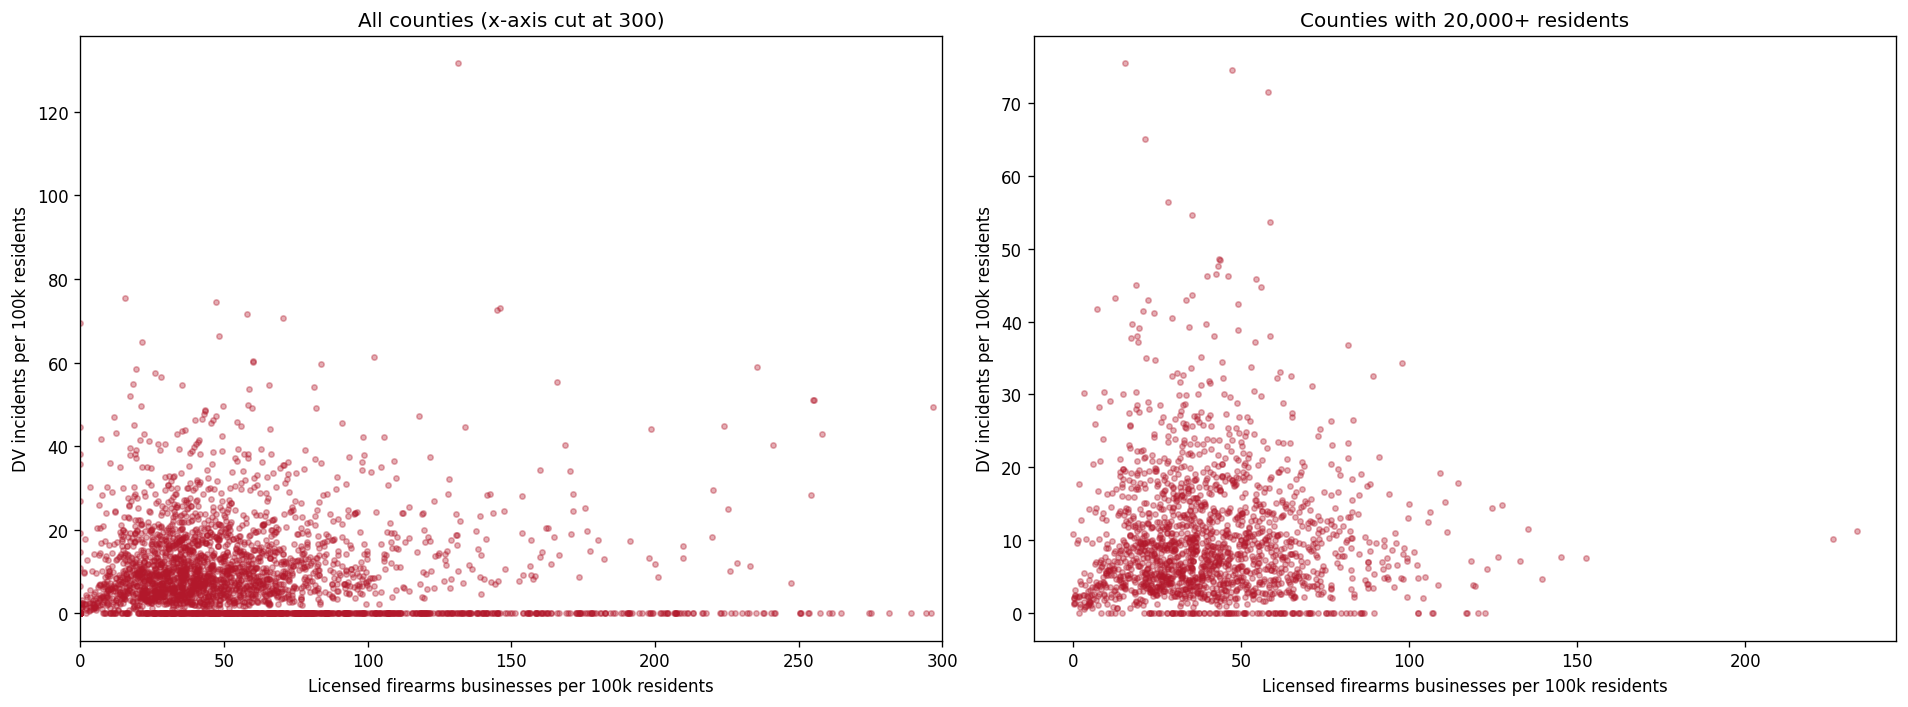

counties off the left chart (FFLs per 100k > 300): 22
DV rate vs FFL rate, all counties:   rho = -0.167, p = 4.6e-21  (n = 3135)
DV rate vs FFL rate, pop >= 20,000:  rho = 0.030, p = 0.21  (n = 1807)


In [16]:
ffl_df = map_gdf[['NAME', 'Domestic Violence per 100k', 'FFLs per 100k', 'Population_2020']].dropna()

fig, axs = plt.subplots(1, 2, figsize=(16, 6), dpi=120)

axs[0].scatter(ffl_df['FFLs per 100k'], ffl_df['Domestic Violence per 100k'], s=10, alpha=0.35, color='#b2182b')
axs[0].set_xlim(0, 300)
axs[0].set_xlabel('Licensed firearms businesses per 100k residents')
axs[0].set_ylabel('DV incidents per 100k residents')
axs[0].set_title('All counties (x-axis cut at 300)')

big = ffl_df[ffl_df['Population_2020'] >= 20000]
axs[1].scatter(big['FFLs per 100k'], big['Domestic Violence per 100k'], s=10, alpha=0.35, color='#b2182b')
axs[1].set_xlabel('Licensed firearms businesses per 100k residents')
axs[1].set_ylabel('DV incidents per 100k residents')
axs[1].set_title('Counties with 20,000+ residents')

plt.tight_layout()
plt.show()

print('counties off the left chart (FFLs per 100k > 300):', (ffl_df['FFLs per 100k'] > 300).sum())

rho, p = stats.spearmanr(ffl_df['FFLs per 100k'], ffl_df['Domestic Violence per 100k'])
print(f'DV rate vs FFL rate, all counties:   rho = {rho:.3f}, p = {p:.2g}  (n = {len(ffl_df)})')

rho, p = stats.spearmanr(big['FFLs per 100k'], big['Domestic Violence per 100k'])
print(f'DV rate vs FFL rate, pop >= 20,000:  rho = {rho:.3f}, p = {p:.2g}  (n = {len(big)})')

Well, that was a fair start. But I don't actually care about counties with high DV incidents. I am specifically interestd in counties where the DV incident rate is high compared to the rate of all gun-involved incidents. I already made that map earlier, so now I want to compare it to income, rurality, and the FFL below.

counties with at least 20 incidents: 1319


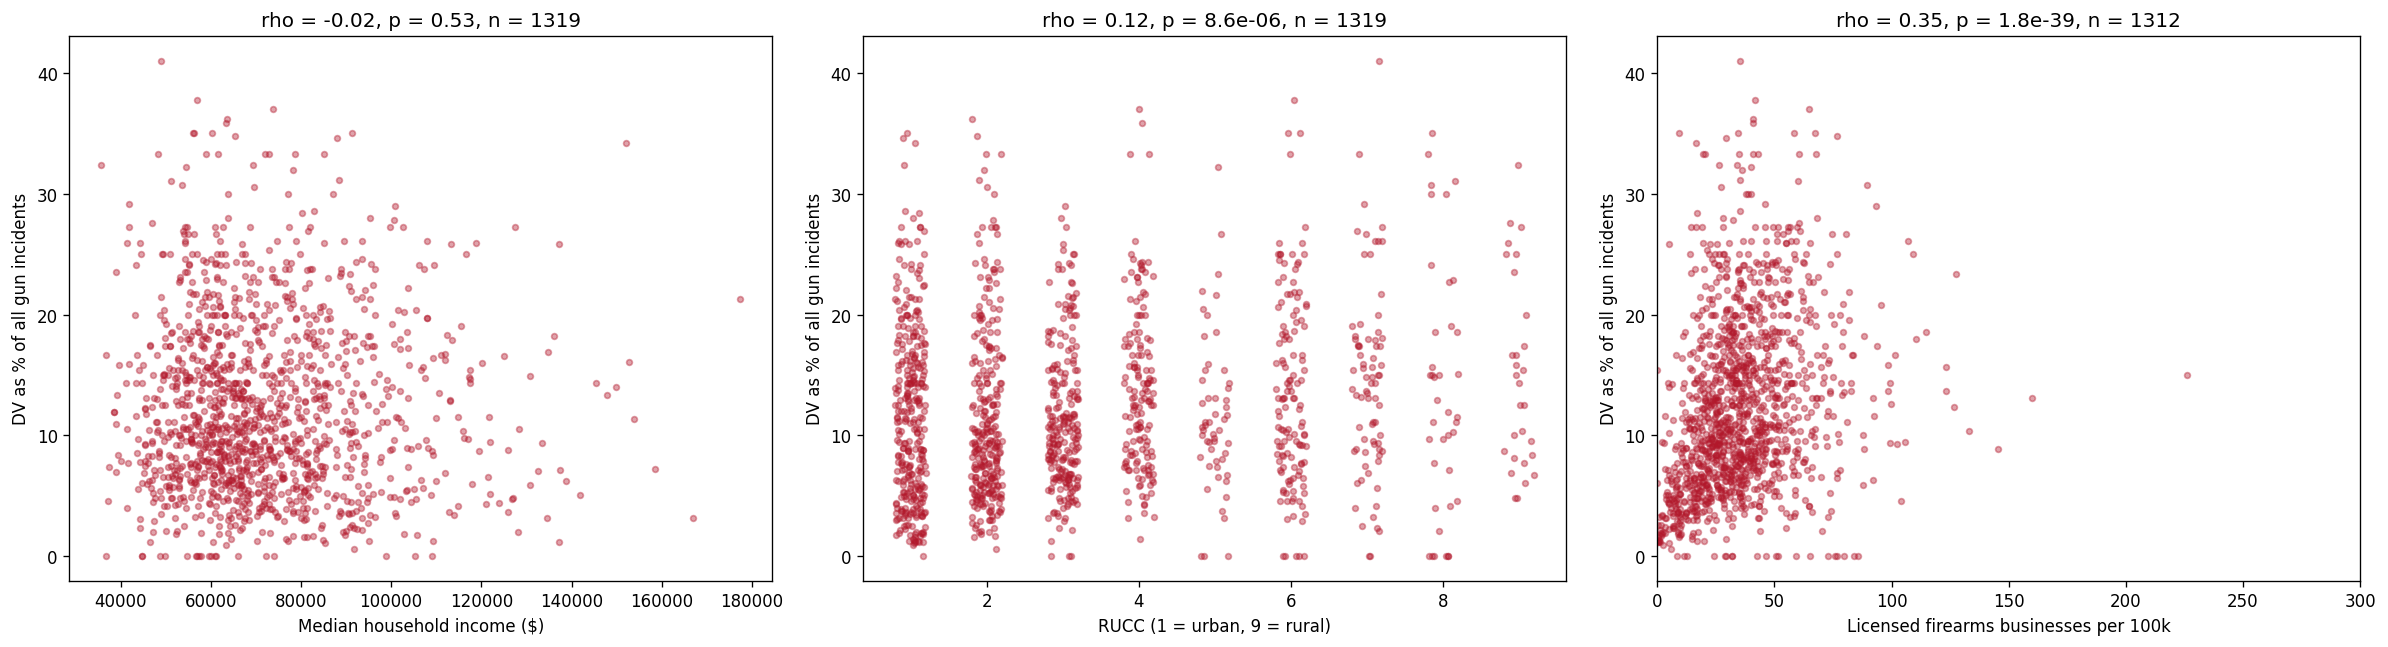

income vs Domestic Violence per 100k: rho = -0.459, p = 1.6e-95  (n = 1816)
income vs Non-DV per 100k: rho = -0.390, p = 6.6e-67  (n = 1816)


In [17]:
min_total = 20   # same cutoff as your earlier DV-share map

# DV share of all gun incidents, only for counties with enough incidents
map_gdf['DV Share of Total'] = np.where(
    map_gdf['Total Incidents'] >= min_total,
    map_gdf['Domestic Violence'] / map_gdf['Total Incidents'] * 100,
    np.nan
)
map_gdf['Median Household Income'] = pd.to_numeric(map_gdf['Median Household Income'], errors='coerce')
share_df = map_gdf.dropna(subset=['DV Share of Total']).copy()
print('counties with at least', min_total, 'incidents:', len(share_df))

# DV share vs each variable
preds = [('Median Household Income', 'Median household income ($)'),
         ('RUCC_2023', 'RUCC (1 = urban, 9 = rural)'),
         ('FFLs per 100k', 'Licensed firearms businesses per 100k')]

fig, axs = plt.subplots(1, 3, figsize=(20, 5.5), dpi=120)
for ax, (col, label) in zip(axs, preds):
    d = share_df[[col, 'DV Share of Total']].dropna()
    x = d[col]
    if col == 'RUCC_2023':
        x = x + np.random.default_rng(0).uniform(-0.2, 0.2, len(d))   # jitter so dots don't stack
    ax.scatter(x, d['DV Share of Total'], s=12, alpha=0.4, color='#b2182b')
    if col == 'FFLs per 100k':
        ax.set_xlim(0, 300)
    rho, p = stats.spearmanr(d[col], d['DV Share of Total'])
    ax.set_title(f'rho = {rho:.2f}, p = {p:.2g}, n = {len(d)}')
    ax.set_xlabel(label)
    ax.set_ylabel('DV as % of all gun incidents')
plt.tight_layout()
plt.show()

# is income tied to DV specifically, or to gun violence in general? (counties of 20,000+)
big = map_gdf[map_gdf['Population_2020'] >= 20000].dropna(subset=['Median Household Income']).copy()
big['Non-DV per 100k'] = (big['Total Incidents'] - big['Domestic Violence']) / big['Population_2020'] * 100000
for col in ['Domestic Violence per 100k', 'Non-DV per 100k']:
    rho, p = stats.spearmanr(big['Median Household Income'], big[col])
    print(f'income vs {col}: rho = {rho:.3f}, p = {p:.2g}  (n = {len(big)})')

Now the results change! FFL and DV incidents are correlated.

- The relationship with income is basically unchanged from before, so it seems that overrall gun violence is correlated with income. Not very surprising.

But the FFL correlation could be noise. It could be DV rates rising. It could be other gun incidents dropping. It's unclear right now.

In [18]:
# what is behind the FFL / DV-share link? DV rate vs non-DV gun violence rate, in the same counties
sh = share_df.dropna(subset=['FFLs per 100k']).copy()
sh['Non-DV per 100k'] = (sh['Total Incidents'] - sh['Domestic Violence']) / sh['Population_2020'] * 100000

for col in ['Domestic Violence per 100k', 'Non-DV per 100k']:
    rho, p = stats.spearmanr(sh['FFLs per 100k'], sh[col])
    print(f'FFLs per 100k vs {col}: rho = {rho:.3f}, p = {p:.2g}  (n = {len(sh)})')

FFLs per 100k vs Domestic Violence per 100k: rho = 0.216, p = 2.6e-15  (n = 1312)
FFLs per 100k vs Non-DV per 100k: rho = -0.085, p = 0.002  (n = 1312)


In [19]:
# does the FFL link hold up when we only look at larger counties?
rules = {
    '20+ incidents (all sizes)':       share_df,
    '20+ incidents and pop >= 20,000': share_df[share_df['Population_2020'] >= 20000],
    '20+ incidents and pop >= 50,000': share_df[share_df['Population_2020'] >= 50000],
}
for name, d in rules.items():
    d = d.dropna(subset=['FFLs per 100k'])
    r1, p1 = stats.spearmanr(d['FFLs per 100k'], d['DV Share of Total'])
    r2, p2 = stats.spearmanr(d['FFLs per 100k'], d['Domestic Violence per 100k'])
    print(f'{name:34s} n = {len(d):4d} | FFL vs DV share: rho = {r1:.3f} | FFL vs DV rate: rho = {r2:.3f}')

20+ incidents (all sizes)          n = 1312 | FFL vs DV share: rho = 0.352 | FFL vs DV rate: rho = 0.216
20+ incidents and pop >= 20,000    n = 1238 | FFL vs DV share: rho = 0.364 | FFL vs DV rate: rho = 0.218
20+ incidents and pop >= 50,000    n =  899 | FFL vs DV share: rho = 0.448 | FFL vs DV rate: rho = 0.231


So the pattern is stronger in counties with a higher base number of incidents. That's fair. The pattern is that places with higher FFL have more DV incidents.

FFL cutoff: 84 per 100k; counties dotted: 33 of 1319
['Bethel, AK', 'Bonner, ID', 'Campbell, WY', 'Cascade, MT', 'Choctaw, OK', 'Douglas, NV', 'Duchesne, UT', 'Dunklin, MO', 'Fairbanks North Star, AK', 'Flathead, MT', 'Franklin, VT', 'Fremont, CO', 'Fremont, WY', 'Gallatin, MT', 'Gila, AZ', 'Kenai Peninsula, AK', 'Lake, MT', 'Lee, IA', 'Lewis and Clark, MT', 'Limestone, TX', 'Marion, MO', 'Matanuska-Susitna, AK', 'Natrona, WY', 'Nez Perce, ID', 'Nicholas, WV', 'Ouachita, AR', 'Park, WY', 'Quay, NM', 'Randolph, WV', 'Rutland, VT', 'Silver Bow, MT', 'Texas, MO', 'Yavapai, AZ']


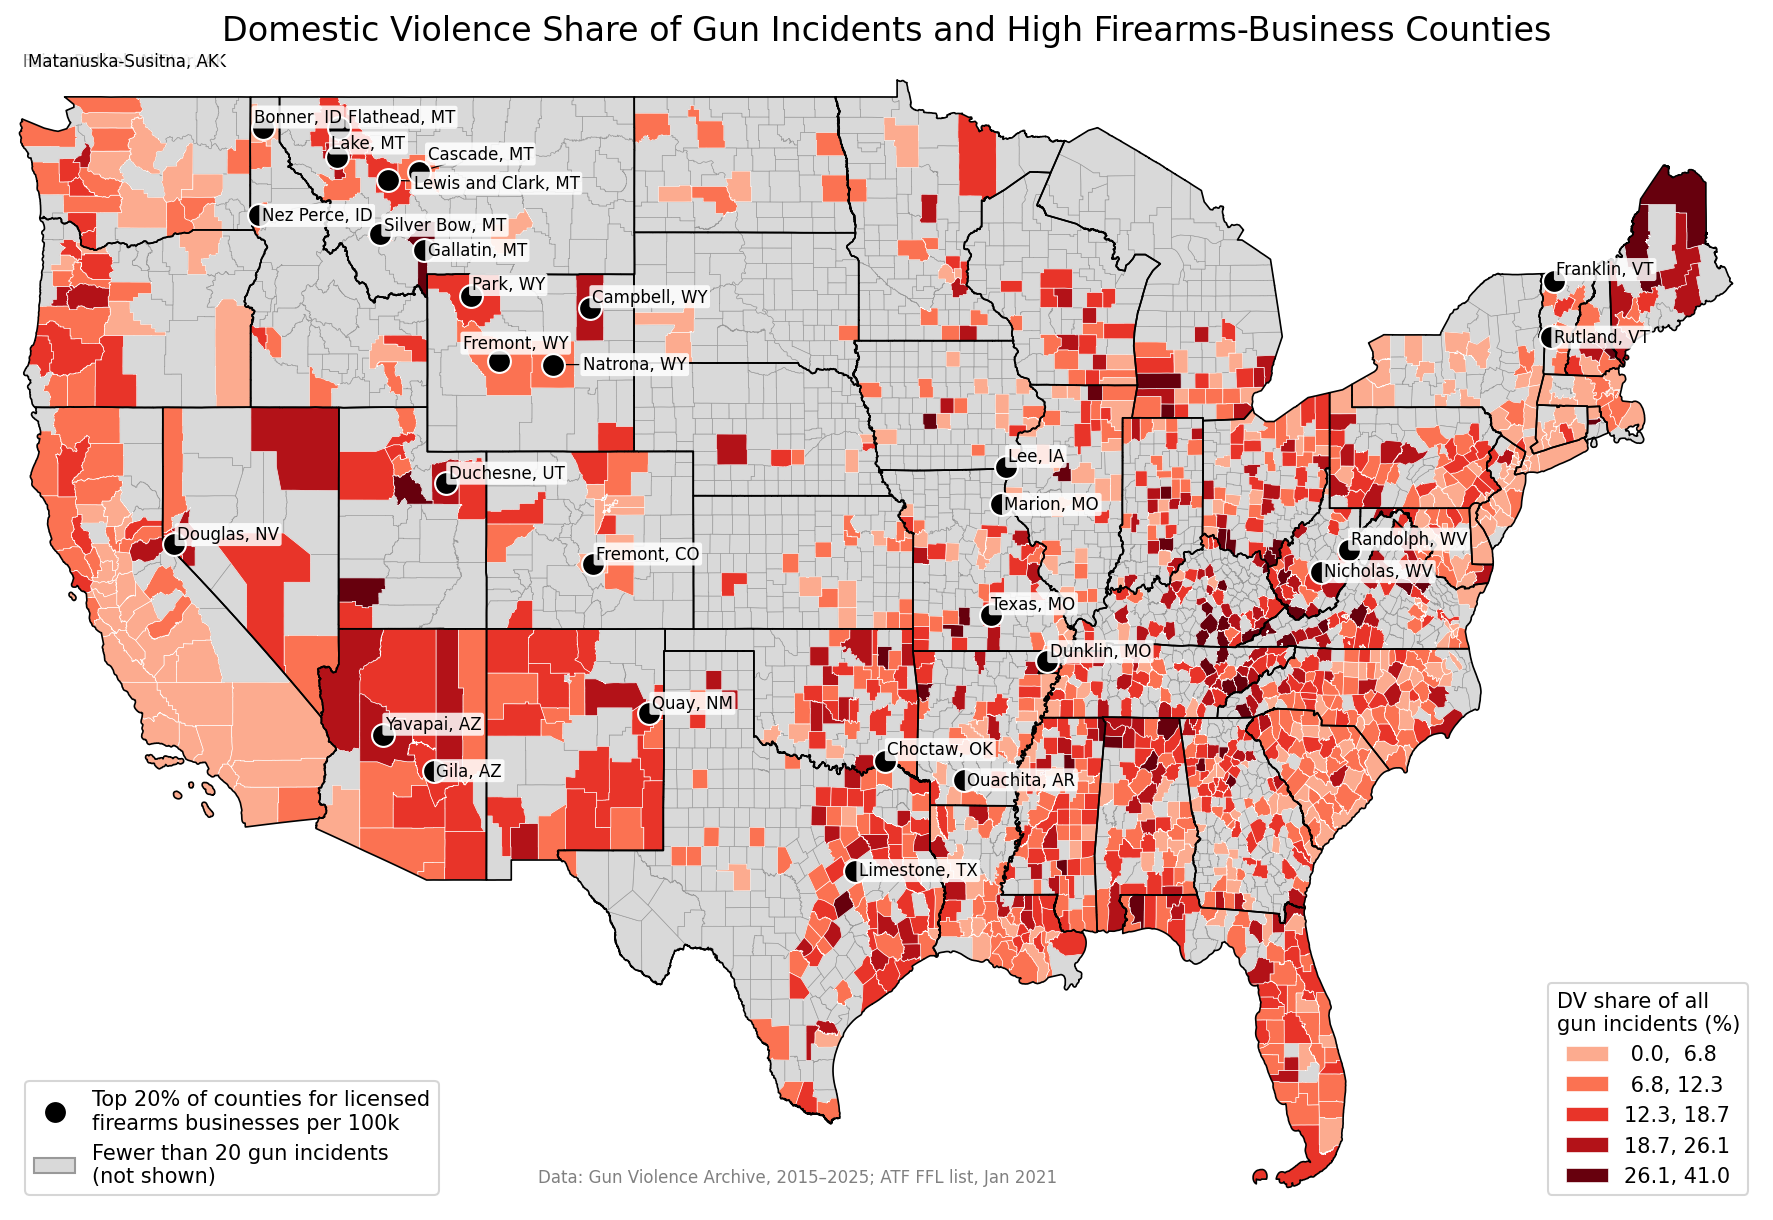

In [22]:
!pip install adjustText -q
from adjustText import adjust_text
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ffl_quantile = 0.8   # 0.8 = top 20% of counties for FFLs per 100k; try 0.9 for fewer, easier-to-read labels

cutoff = map_gdf['FFLs per 100k'].quantile(ffl_quantile)
excluded = map_gdf[map_gdf['DV Share of Total'].isna()]
included = map_gdf.dropna(subset=['DV Share of Total'])

# high-FFL counties among those with enough incidents; centroids from a projected CRS
hi = included[included['FFLs per 100k'] >= cutoff].copy()
hi_pts = hi.to_crs('EPSG:5070').geometry.centroid.to_crs('EPSG:4326')

# label = county name + state abbreviation (many county names repeat across states)
fips_to_state = dict(zip(rucc['FIPS'], rucc['State']))
hi['Label'] = hi['NAME'] + ', ' + hi['FIPS'].map(fips_to_state)
print(f'FFL cutoff: {cutoff:.0f} per 100k; counties dotted: {len(hi)} of {len(included)}')
print(sorted(hi['Label']))

fig, ax = plt.subplots(figsize=(15, 10), dpi=150)

excluded.plot(ax=ax, color='#d9d9d9', edgecolor='#999999', linewidth=0.3)
included.plot(
    ax=ax, column='DV Share of Total', cmap=reds_truncated,
    scheme='natural_breaks', k=5,
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': 'DV share of all\ngun incidents (%)', 'loc': 'lower right', 'fmt': '{:,.1f}'}
)
share_legend = ax.get_legend()
ax.add_artist(share_legend)   # keep this legend when adding the second one

states.boundary.plot(ax=ax, color='black', linewidth=0.8)

# overlay: large black dots at county centroids
hi_pts.plot(ax=ax, color='black', markersize=120, edgecolor='white', linewidth=1.0, zorder=5)

key = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markeredgecolor='white', markersize=11,
           label='Top 20% of counties for licensed\nfirearms businesses per 100k'),
    Patch(facecolor='#d9d9d9', edgecolor='#999999', label='Fewer than 20 gun incidents\n(not shown)'),
]
ax.legend(handles=key, loc='lower left', frameon=True)

ax.text(0.30, 0.02, 'Data: Gun Violence Archive, 2015–2025; ATF FFL list, Jan 2021', transform=ax.transAxes, fontsize=8, color='gray')
ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)

# county labels, nudged apart so they don't overlap
texts = [
    ax.text(pt.x, pt.y, hi.loc[i, 'Label'], fontsize=8, zorder=6,
            bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85))
    for i, pt in hi_pts.items()
]
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='black', lw=0.6))

ax.set_title('Domestic Violence Share of Gun Incidents and High Firearms-Business Counties', fontsize=16)
ax.axis('off')
plt.show()

# notes to myself

### fa24

### 2023

TODO if anything go thru gpd again esp as more features being added!
<br>

the whole course, geo dat sci: [oct2023 not super urgent; skimmed thru it already]
https://darribas.org/gds_course/content/home.html

<br>oct2023 found 1 more; already incorporated most useful stuff , still  a useful reference:

old  version:
https://automating-gis-processes.github.io/CSC/index.html

new version:
https://autogis-site.readthedocs.io/en/latest/



<br>
LATER/MAYBE: [oct2023 but meh not clear advantage over gpd/folium]
 basemap! guess the first one! used to use it, but dead, depreciated in favor of cartopy
https://jakevdp.github.io/PythonDataScienceHandbook/04.13-geographic-data-with-basemap.html